# U-Net: image segmentation on Oxford-IIIT Pets

**Goal:** build a U-Net by hand to understand it, train a U-Net with a pretrained encoder to cut pets out of photos, then learn how to make it more accurate, faster, and how it fits into modern segmentation research.

**What is segmentation?** Classification answers *"what is in the image?"* with one label. Segmentation answers *"which pixels belong to what?"* with one label **per pixel**. Output is a mask the same size as the image.

| Task | Output for a 256x256 image |
| --- | --- |
| Classification | 1 number (class) |
| Detection | a few boxes |
| Semantic segmentation | 256x256 class map (this notebook) |
| Instance segmentation | one mask per object (dog #1, dog #2) |
| Panoptic segmentation | semantic + instance together |

**Dataset:** Oxford-IIIT Pet, 37 breeds of cats and dogs, each photo with a pixel mask (trimap). We turn it into a binary task: **pet vs background**. Small enough to train on one free Colab T4.

**Two runs so far**

| Run | Model | Image size | Train images | Epochs | Val IoU | + flip TTA |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | hand-built `UNet` (7.8M params, random init), Mac MPS | 128 | 2000 | 12 | 0.818 | 0.822 |
| 2 | `smp.Unet` with ImageNet ResNet-34 encoder, Colab T4 | 256 | 3680 | 25 | 0.911 | 0.915 |

The outputs saved in this notebook are from run 2.

**Plan**
1. Load data and look at it
2. Build U-Net block by block (then train the pretrained version)
3. Loss (BCE + Dice) and metrics (IoU, Dice)
4. Train, plot, look at predictions
5. Inference speed: fp16, channels_last, batch size, test-time augmentation
6. Theory: how to improve accuracy, speed, and what is new in the field

## 1. Setup

In [33]:
# Simple Setup: Ensure libraries are ready
!pip install -q segmentation-models-pytorch albumentations

import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [34]:
import time, segmentation_models_pytorch as smp
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from torchvision.transforms import v2 as T
from torchvision import tv_tensors

# Set seeds for reproducibility
torch.manual_seed(0)
random.seed(0)
np.random.seed(0)

# Configuration parameters
IMG = 256          # Image size
BATCH = 16
EPOCHS = 25
N_TRAIN, N_VAL = 3680, 400

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Active Device:", device)

Active Device: cuda


In [35]:
import torch
import os
from torchvision import datasets

# 1. Verify GPU availability
print("Is CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Device Name:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    print("No GPU detected, using CPU (or MPS if on Apple Silicon)")
    device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# 2. Trigger downloading of the dataset explicitly
print("Downloading/checking Oxford-IIIT Pet dataset...")
os.makedirs("../data", exist_ok=True)
_ = datasets.OxfordIIITPet("../data", split="trainval", target_types="segmentation", download=True)
_ = datasets.OxfordIIITPet("../data", split="test", target_types="segmentation", download=True)
print("Dataset ready!")

Is CUDA available: True
GPU Device Name: Tesla T4
Downloading/checking Oxford-IIIT Pet dataset...
Dataset ready!


## 2. Data

The pet masks are **trimaps**: `1 = pet`, `2 = background`, `3 = border` (the uncertain edge). We map them to binary: `pet + border -> 1`, `background -> 0`.

**Important detail:** the image and its mask must get the **same** geometric transform (same flip, same crop). `torchvision.transforms.v2` does this when the mask is wrapped as `tv_tensors.Mask`. Masks are resized with **nearest** interpolation, never bilinear, otherwise you invent fake labels like 0.5.

In [36]:
train_tf = T.Compose([
    T.RandomResizedCrop((IMG, IMG), scale=(0.5, 1.0)),
    T.RandomHorizontalFlip(), T.RandomRotation(15),
    T.ColorJitter(0.3, 0.3, 0.3, 0.05),        # only changes the image, not the mask
])
eval_tf = T.Resize((IMG, IMG))

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class PetSeg(torch.utils.data.Dataset):
    def __init__(self, split, tf):
        self.ds = datasets.OxfordIIITPet("../data", split=split, target_types="segmentation", download=True)
        self.tf = tf

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, i):
        img, trimap = self.ds[i]
        img = tv_tensors.Image(T.functional.pil_to_tensor(img))
        mask = tv_tensors.Mask(T.functional.pil_to_tensor(trimap))
        img, mask = self.tf(img, mask)                     # same flip for both
        img = (img.float() / 255 - MEAN) / STD
        mask = ((mask == 1) | (mask == 3)).float()                         # pet + border = 1, background = 0
        return img, mask

full_train = PetSeg("trainval", train_tf)
full_val = PetSeg("test", eval_tf)
train_ds = Subset(full_train, random.sample(range(len(full_train)), N_TRAIN))
val_ds = Subset(full_val, random.sample(range(len(full_val)), N_VAL))

train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=BATCH, num_workers=0)
print(len(train_ds), "train,", len(val_ds), "val")

3680 train, 400 val


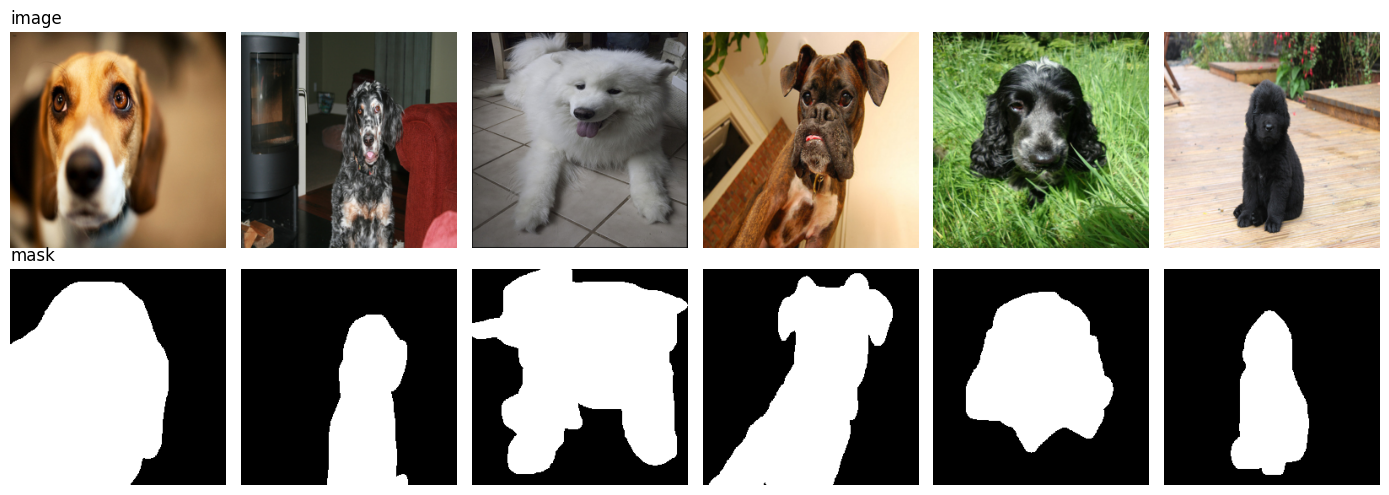

fraction of pet pixels: 0.3768043518066406


In [37]:
def denorm(x):
    return (x.cpu() * STD + MEAN).clamp(0, 1).permute(1, 2, 0)

imgs, masks = next(iter(val_dl))
fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for i in range(6):
    ax[0, i].imshow(denorm(imgs[i])); ax[0, i].axis("off")
    ax[1, i].imshow(masks[i, 0], cmap="gray"); ax[1, i].axis("off")
ax[0, 0].set_title("image", loc="left"); ax[1, 0].set_title("mask", loc="left")
plt.tight_layout(); plt.show()
print("fraction of pet pixels:", masks.mean().item())

## 3. The U-Net idea

U-Net (Ronneberger et al., 2015) was made for biomedical images with very little training data. Its shape is a **U**:

```
input 3x128x128
  │
  enc1 ── DoubleConv ─ 32x128x128 ────────────── skip ─────────────┐
  │ maxpool                                                         │
  enc2 ── DoubleConv ─ 64x64x64 ──────────── skip ──────────┐       │
  │ maxpool                                                  │       │
  enc3 ── DoubleConv ─ 128x32x32 ──────── skip ───────┐     │       │
  │ maxpool                                           │     │       │
  enc4 ── DoubleConv ─ 256x16x16 ───── skip ───┐     │     │       │
  │ maxpool                                    │     │     │       │
  bottleneck ─ DoubleConv ─ 512x8x8            │     │     │       │
  │ upconv ──────────────────────────► concat ─┘     │     │       │
  dec4 ─ 256x16x16                                   │     │       │
  │ upconv ──────────────────────────────────► concat┘     │       │
  dec3 ─ 128x32x32                                         │       │
  │ upconv ────────────────────────────────────────► concat┘       │
  dec2 ─ 64x64x64                                                  │
  │ upconv ──────────────────────────────────────────────► concat ─┘
  dec1 ─ 32x128x128
  │ 1x1 conv
  output 1x128x128  (one logit per pixel)
```

Sizes above are for the hand-built `UNet` (`base=32`) at 128px. At 256px every spatial size doubles. The `smp.Unet("resnet34")` trained below has the same U shape, but its encoder is a ResNet-34 with five downsampling steps (channels 64, 64, 128, 256, 512), so a 256px input reaches 8x8 at the bottleneck.

**Three parts:**
- **Encoder (left, going down):** conv + pool. Each step halves the size and doubles the channels. The net learns *what* is there (a dog), but loses *where* exactly.
- **Decoder (right, going up):** upsample back to full size. It must rebuild exact edges.
- **Skip connections (horizontal arrows):** copy the encoder features at each scale and **concatenate** them to the decoder. The encoder still has the sharp spatial detail the bottleneck threw away. This is the key trick.

**Why concat and not add (like ResNet)?** Concat keeps both feature sets separate and lets the next conv decide how to mix them. ResNet's add assumes both tensors mean the same thing; here one is "low-level edges" and one is "high-level semantics".

**Receptive field:** each pool doubles how much of the image one pixel "sees". 4 pools lets the bottleneck see most of a 128px image, so it knows context (this blob is a cat's ear, not the sofa).

### Building block: DoubleConv

Two `3x3 conv -> BatchNorm -> ReLU`. `padding=1` keeps the size, so the output mask is exactly the input size. (The original paper used no padding and cropped the skip features; padding is simpler and is what everyone does now.)

In [38]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.net(x)

class Down(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(nn.MaxPool2d(2), DoubleConv(cin, cout))

    def forward(self, x):
        return self.net(x)

class Up(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.up = nn.ConvTranspose2d(cin, cin // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(cin, cout)

    def forward(self, x, skip):
        x = self.up(x)
        return self.conv(torch.cat([skip, x], dim=1))

In [39]:
class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.inc = DoubleConv(in_ch, c[0])
        self.down1 = Down(c[0], c[1])
        self.down2 = Down(c[1], c[2])
        self.down3 = Down(c[2], c[3])
        self.down4 = Down(c[3], c[4])
        self.up1 = Up(c[4], c[3])
        self.up2 = Up(c[3], c[2])
        self.up3 = Up(c[2], c[1])
        self.up4 = Up(c[1], c[0])
        self.out = nn.Conv2d(c[0], out_ch, 1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.out(x)

model = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

## 4. Loss and metrics

### Loss
- **BCE (binary cross-entropy):** judges every pixel on its own. Stable gradients, but if 90% of pixels are background the net can get low loss by mostly saying "background".
- **Dice loss:** `1 - 2|P∩G| / (|P|+|G|)`. Measures overlap of the whole mask, so it does not care how many background pixels there are. Handles class imbalance, but gradients can be noisy alone.
- **BCE + Dice:** the standard combo. BCE gives smooth per-pixel learning, Dice pushes overall overlap.

Others worth knowing: **Focal loss** (down-weights easy pixels), **Tversky** (tune false-positive vs false-negative cost), **Lovász hinge** (directly optimizes IoU), **boundary losses** (care about edges).

### Metrics
- **Pixel accuracy:** % of correct pixels. **Misleading.** A net that predicts all background on an image with 5% pet scores 95%.
- **IoU (Jaccard):** `|P∩G| / |P∪G|`. The main segmentation metric. mIoU = mean IoU over classes.
- **Dice (F1):** `2|P∩G| / (|P|+|G|)`. Always ≥ IoU; common in medical imaging.

In [40]:
def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum(dim=(1, 2, 3))
    union = p.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (union + eps)).mean()

def loss_fn(logits, target):
    return F.binary_cross_entropy_with_logits(logits, target) + dice_loss(logits, target)

@torch.no_grad()
def metrics(logits, target, thr=0.5):
    pred = (torch.sigmoid(logits) > thr).float()
    inter = (pred * target).sum(dim=(1, 2, 3))
    p_sum, t_sum = pred.sum(dim=(1, 2, 3)), target.sum(dim=(1, 2, 3))
    iou = (inter + 1e-6) / (p_sum + t_sum - inter + 1e-6)
    dice = (2 * inter + 1e-6) / (p_sum + t_sum + 1e-6)
    acc = (pred == target).float().mean(dim=(1, 2, 3))
    return iou.sum().item(), dice.sum().item(), acc.sum().item()

## 5. Train

The `UNet` class above is for understanding the architecture. The training run uses `smp.Unet("resnet34", encoder_weights="imagenet")`: same U shape, but the encoder already knows ImageNet features.

Setup: 256px, all 3680 trainval images, 400 test images for validation, batch 16, 25 epochs. AdamW (lr 3e-4, weight decay 1e-4) with a cosine schedule stepped every batch. We keep the checkpoint with the best validation IoU.

To train the hand-built version instead, replace the `model = smp.Unet(...)` line with `model = UNet().to(device)`.

In [41]:
# Ensure data loaders are defined before training
if 'train_dl' not in globals():
    train_ds = Subset(full_train, random.sample(range(len(full_train)), N_TRAIN))
    val_ds = Subset(full_val, random.sample(range(len(full_val)), N_VAL))
    train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True, num_workers=2)
    val_dl = DataLoader(val_ds, batch_size=BATCH, num_workers=0)

@torch.no_grad()
def evaluate(model, dl):
    model.eval()
    tot_loss = tot_iou = tot_dice = tot_acc = n = 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        tot_loss += loss_fn(logits, y).item() * len(x)
        i, d, a = metrics(logits, y)
        tot_iou += i; tot_dice += d; tot_acc += a; n += len(x)
    return tot_loss / n, tot_iou / n, tot_dice / n, tot_acc / n

# Initialize model and optimization
model = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=1).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(train_dl))

hist = {"train_loss": [], "val_loss": [], "val_iou": [], "val_dice": [], "val_acc": []}
best_iou = 0
best_state = None

for epoch in range(EPOCHS):
    model.train()
    run_loss = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        opt.step()
        sched.step()
        run_loss += loss.item() * len(x)

    vl, viou, vdice, vacc = evaluate(model, val_dl)
    hist["train_loss"].append(run_loss / len(train_ds))
    hist["val_loss"].append(vl)
    hist["val_iou"].append(viou)
    hist["val_dice"].append(vdice)
    hist["val_acc"].append(vacc)

    if viou > best_iou:
        best_iou = viou
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    print(f"Epoch {epoch + 1:02d} | Train Loss: {run_loss / len(train_ds):.3f} | Val Loss: {vl:.3f} | Val IoU: {viou:.3f}")

model.load_state_dict(best_state)
print(f"Training complete. Best Val IoU: {best_iou:.3f}")

Epoch 01 | Train Loss: 0.392 | Val Loss: 0.272 | Val IoU: 0.877
Epoch 02 | Train Loss: 0.286 | Val Loss: 0.241 | Val IoU: 0.881
Epoch 03 | Train Loss: 0.253 | Val Loss: 0.267 | Val IoU: 0.869
Epoch 04 | Train Loss: 0.238 | Val Loss: 0.260 | Val IoU: 0.872
Epoch 05 | Train Loss: 0.216 | Val Loss: 0.213 | Val IoU: 0.894
Epoch 06 | Train Loss: 0.218 | Val Loss: 0.239 | Val IoU: 0.881
Epoch 07 | Train Loss: 0.201 | Val Loss: 0.210 | Val IoU: 0.898
Epoch 08 | Train Loss: 0.185 | Val Loss: 0.205 | Val IoU: 0.897
Epoch 09 | Train Loss: 0.176 | Val Loss: 0.213 | Val IoU: 0.901
Epoch 10 | Train Loss: 0.173 | Val Loss: 0.201 | Val IoU: 0.902
Epoch 11 | Train Loss: 0.162 | Val Loss: 0.205 | Val IoU: 0.899
Epoch 12 | Train Loss: 0.161 | Val Loss: 0.207 | Val IoU: 0.900
Epoch 13 | Train Loss: 0.162 | Val Loss: 0.204 | Val IoU: 0.903
Epoch 14 | Train Loss: 0.154 | Val Loss: 0.196 | Val IoU: 0.908
Epoch 15 | Train Loss: 0.145 | Val Loss: 0.190 | Val IoU: 0.909
Epoch 16 | Train Loss: 0.138 | Val Loss:

In [42]:
import os; os.makedirs("../outputs", exist_ok=True)

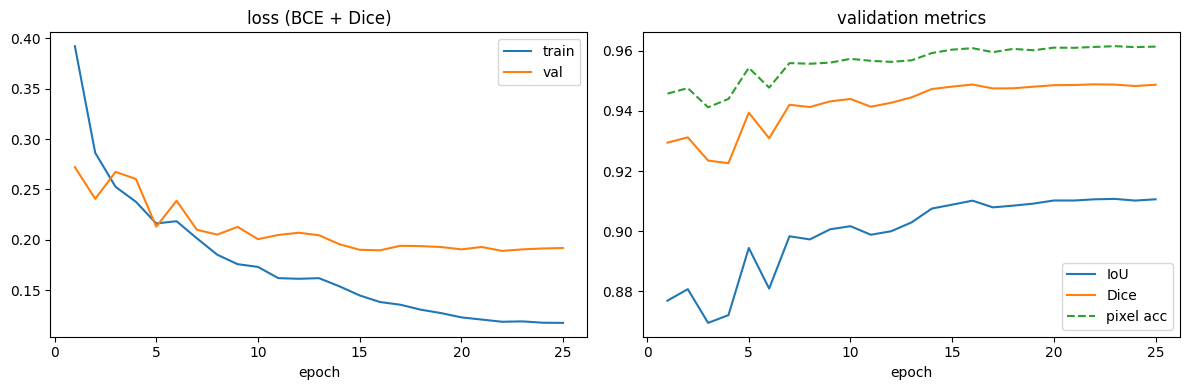

In [43]:
ep = range(1, EPOCHS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="val")
ax[0].set_title("loss (BCE + Dice)"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, hist["val_iou"], label="IoU"); ax[1].plot(ep, hist["val_dice"], label="Dice")
ax[1].plot(ep, hist["val_acc"], label="pixel acc", linestyle="--")
ax[1].set_title("validation metrics"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("../outputs/unet_training.png", dpi=120); plt.show()

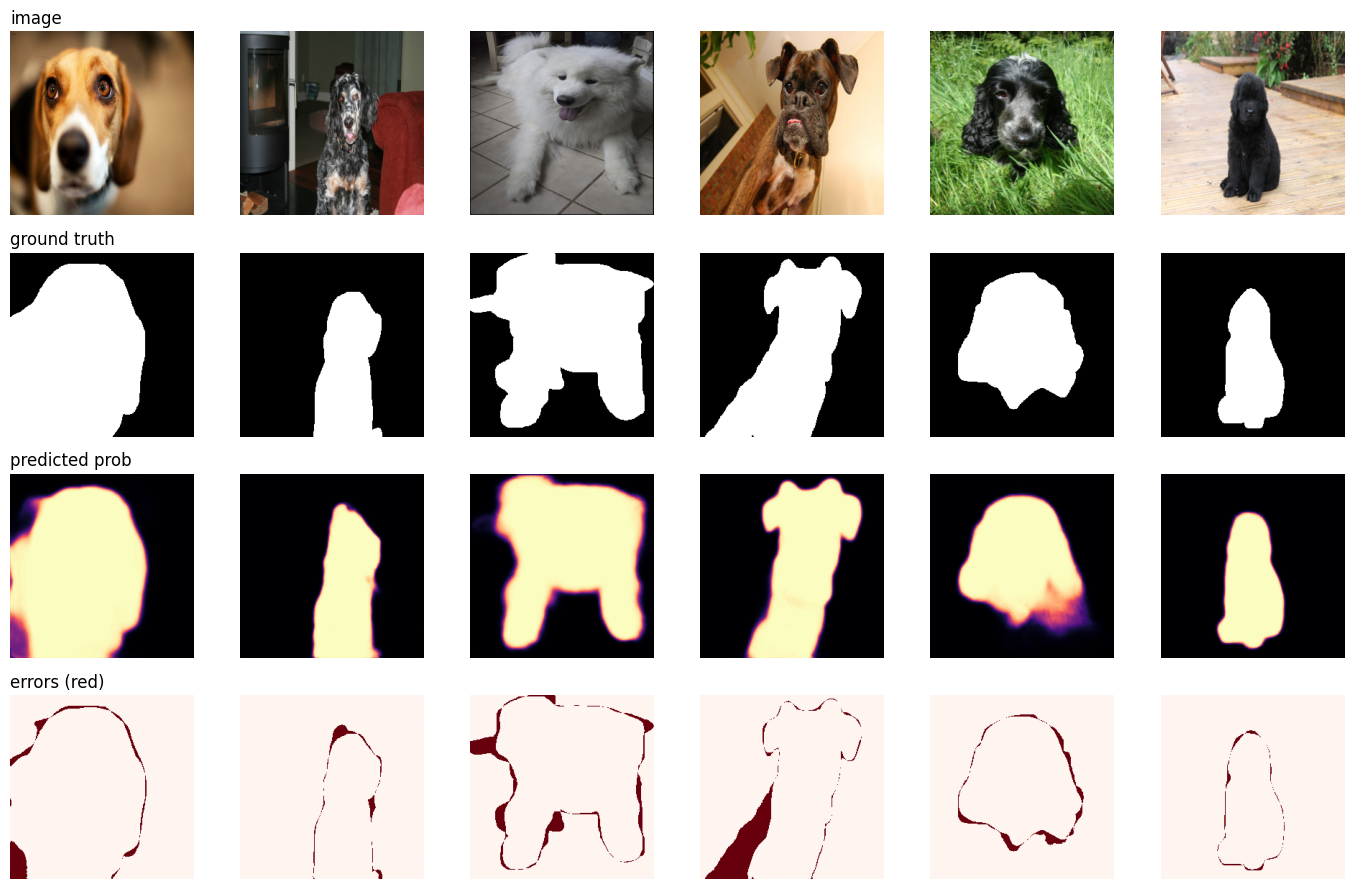

In [44]:
model.eval()
imgs, masks = next(iter(val_dl))
with torch.no_grad():
    probs = torch.sigmoid(model(imgs.to(device))).cpu()

fig, ax = plt.subplots(4, 6, figsize=(14, 9))
for i in range(6):
    pred = (probs[i, 0] > 0.5).float()
    err = (pred != masks[i, 0]).float()
    ax[0, i].imshow(denorm(imgs[i]))
    ax[1, i].imshow(masks[i, 0], cmap="gray")
    ax[2, i].imshow(probs[i, 0], cmap="magma", vmin=0, vmax=1)
    ax[3, i].imshow(err, cmap="Reds")
    for r in range(4):
        ax[r, i].axis("off")
for r, name in enumerate(["image", "ground truth", "predicted prob", "errors (red)"]):
    ax[r, 0].set_title(name, loc="left")
plt.tight_layout(); plt.savefig("../outputs/unet_predictions.png", dpi=120); plt.show()

**Read the error row.** With the pretrained encoder most mistakes are now:
1. **Thin lines along edges** (fur, ears, tails). The trimap border is fuzzy there anyway. Boundary-aware losses and higher resolution help.
2. **Pet regions that blend into the background.** The boxer (4th column) loses its lower body against a brown wall, and the spaniel (5th) loses chest fur against dark grass. The probability map shows the model is unsure there rather than confidently wrong.

The from-scratch run also made blobs on background that looked furry (sunflowers, a wooden fence). Those are gone: pretrained features know what a whole pet looks like, not just its texture.

## 6. Inference: speed

Training speed and inference speed are different problems. At inference we can:
1. Turn off gradients: `torch.inference_mode()`
2. Use half precision (fp16 / bf16): half the memory traffic, uses tensor cores on GPUs
3. Use `channels_last` memory layout: convs on GPUs are faster with NHWC
4. Use bigger batches: more images per second (throughput), but each request waits longer (latency)
5. Fuse Conv+BN (see `resnet.ipynb`), `torch.compile`, export to ONNX / TensorRT / CoreML

Below we measure some of these. Numbers depend a lot on your device.

In [45]:
def sync():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

@torch.inference_mode()
def bench(m, bs, dtype=torch.float32, channels_last=False, iters=20):
    x = torch.randn(bs, 3, IMG, IMG, device=device, dtype=dtype)
    if channels_last:
        x = x.to(memory_format=torch.channels_last)
    for _ in range(3): m(x)            # warmup
    sync(); t = time.time()
    for _ in range(iters): m(x)
    sync()
    dt = (time.time() - t) / iters
    return dt * 1000, bs / dt          # ms per batch, images per second

import copy
results = []
m32 = copy.deepcopy(model).eval()
for bs in [1, 16, 64]:
    ms, ips = bench(m32, bs)
    results.append(("fp32", bs, ms, ips))

if device.type != "cpu":
    m16 = copy.deepcopy(model).eval().half()
    for bs in [1, 16, 64]:
        ms, ips = bench(m16, bs, dtype=torch.float16)
        results.append(("fp16", bs, ms, ips))
    mcl = copy.deepcopy(model).eval().half().to(memory_format=torch.channels_last)
    ms, ips = bench(mcl, 64, dtype=torch.float16, channels_last=True)
    results.append(("fp16 + channels_last", 64, ms, ips))

print(f"{'setting':22s} {'batch':>5s} {'ms/batch':>10s} {'img/s':>8s}")
for name, bs, ms, ips in results:
    print(f"{name:22s} {bs:5d} {ms:10.2f} {ips:8.0f}")

setting                batch   ms/batch    img/s
fp32                       1      15.82       63
fp32                      16      69.13      231
fp32                      64     255.36      251
fp16                       1       6.60      151
fp16                      16      33.90      472
fp16                      64     129.04      496
fp16 + channels_last      64     108.68      589


**What to notice**
- batch 1 has the lowest **latency** (ms), batch 64 the highest **throughput** (img/s). A phone app cares about latency; a server processing a folder of images cares about throughput.
- fp16 usually helps more on GPUs with tensor cores (NVIDIA) than on Apple MPS or CPU. On this T4, fp16 roughly doubles throughput at batch 64 (251 to 496 img/s) and `channels_last` adds about 19% more (589 img/s). On a Mac (run 1) fp16 only helped at batch 1.
- Check accuracy after any speed trick. fp16 should give nearly the same IoU:

In [46]:
import copy
if device.type != "cpu":
    _, iou32, _, _ = evaluate(model, val_dl)
    m16 = copy.deepcopy(model).eval().half()
    tot = n = 0
    with torch.inference_mode():
        for x, y in val_dl:
            logits = m16(x.to(device).half()).float()
            tot += metrics(logits, y.to(device))[0]; n += len(x)
    print(f"IoU fp32 {iou32:.4f} | fp16 {tot / n:.4f}")

IoU fp32 0.9107 | fp16 0.9107


## 7. Inference: free accuracy

Two tricks that need **no retraining**:

**Test-time augmentation (TTA):** predict on the image and its horizontal flip, flip the second prediction back, average. Errors that are not symmetric cancel out. Costs 2x inference time.

**Threshold tuning:** 0.5 is not magic. Sweep thresholds on validation data and pick the best one. (Do this on a validation set, never the test set, or you are cheating.)

In [47]:
@torch.inference_mode()
def eval_with(model, dl, tta=False, thr=0.5):
    model.eval()
    tot = n = 0
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        p = torch.sigmoid(model(x))
        if tta:
            p_flip = torch.sigmoid(model(torch.flip(x, dims=[3])))
            p = (p + torch.flip(p_flip, dims=[3])) / 2
        logits = torch.logit(p.clamp(1e-6, 1 - 1e-6))   # back to logits for metrics()
        tot += metrics(logits, y, thr)[0]; n += len(x)
    return tot / n

print(f"IoU plain:          {eval_with(model, val_dl):.4f}")
print(f"IoU with flip TTA:  {eval_with(model, val_dl, tta=True):.4f}")
for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    print(f"  threshold {thr}: IoU {eval_with(model, val_dl, tta=True, thr=thr):.4f}")

IoU plain:          0.9107
IoU with flip TTA:  0.9146
  threshold 0.3: IoU 0.9094
  threshold 0.4: IoU 0.9135
  threshold 0.5: IoU 0.9146
  threshold 0.6: IoU 0.9124
  threshold 0.7: IoU 0.9086


---
# 8. Theory: how to make it better

## 8.1 Improving accuracy

Roughly ordered by **how much gain per effort** on a small dataset like this:

1. **Pretrained encoder (biggest win, done in run 2).** Replace a random-init encoder with a ResNet / EfficientNet / ConvNeXt trained on ImageNet. It already knows edges, fur, and object shapes. Library: `segmentation_models_pytorch` -> `smp.Unet("resnet34", encoder_weights="imagenet")`. Often +5-10 IoU points on small data. Here run 1 to run 2 went from 0.818 to 0.911, together with the changes in 3 and 4. Same idea as `cnn.py` in this repo (transfer learning), applied to segmentation.
2. **More / better data augmentation.** Random resized crop, rotation, scale, elastic deform (the original U-Net paper relied on this), brightness/contrast. Library: `albumentations`. Remember: geometric transforms on image **and** mask, color transforms on image only.
3. **Train longer, use all data (done in run 2).** Run 1 used 2000 of 3680 images and 12 epochs; run 2 uses all of them for 25 epochs. Val loss now flattens after about epoch 15, so more epochs alone will not add much.
4. **Higher resolution (256px in run 2).** 128px loses fine fur and tails. 384 could clean up edges further, at about 2.25x the compute of 256.
5. **Better loss.** BCE+Dice is a good default. Add Focal for hard pixels, Lovász to optimize IoU directly, or a boundary loss for edges.
6. **Architecture upgrades:**
   - **Attention U-Net** (2018): attention gates on skip connections suppress irrelevant background features.
   - **UNet++** (2018): nested dense skip paths to reduce the "semantic gap" between encoder and decoder features.
   - **Residual blocks** inside DoubleConv (ResUNet).
   - **Deep supervision:** add a loss on intermediate decoder outputs, better gradients for deep layers.
   - **ASPP / dilated convs** (DeepLab family) for multi-scale context.
7. **Regularization:** dropout in the bottleneck, weight decay, EMA of weights (keep a moving average of the weights for eval, usually +small gain, almost free).
8. **Post-processing:** keep only the largest connected component (one pet per photo), fill holes, morphological open/close. CRFs were popular before; rarely needed now.
9. **Ensembles + TTA:** average several models / flips / scales. Kaggle winners do this; costly at inference.

**Debugging order when results are bad:** look at the data and masks first (alignment bugs are common), overfit a single batch (loss should go to ~0), then scale up.

## 8.2 Improving training speed

- **Mixed precision (AMP):** `torch.autocast(device_type, dtype=torch.bfloat16)` + `GradScaler` for fp16. ~2x faster on modern GPUs, half the memory.
- **DataLoader:** `num_workers>0`, `pin_memory=True`, pre-resize images on disk. Often the GPU is waiting for JPEG decoding.
- **`torch.compile(model)`:** fuses ops; 1.3-2x on GPU after compile warmup.
- **channels_last** memory format for convs.
- **Larger batch + higher LR** (with warmup), or **OneCycle** schedule to converge in fewer epochs.
- **Pretrained encoder** also converges much faster.

## 8.3 Improving inference speed / deploying

| Technique | Idea | Typical gain |
| --- | --- | --- |
| fp16 / bf16 | half the bits | ~2x on GPU, ~0 IoU loss |
| INT8 quantization (PTQ or QAT) | 8-bit weights and activations | 2-4x on CPU / edge, small IoU loss; QAT recovers it |
| Conv+BN fusion | merge BN into conv weights | 5-15%, exact same output |
| Fewer channels (`base=16`) | 4x fewer FLOPs | big speedup, some IoU loss |
| Depthwise-separable convs | MobileNet-style blocks | 5-10x fewer FLOPs |
| Lightweight encoder | MobileNetV3 / EfficientNet-Lite | real-time on phones |
| Pruning | remove low-importance channels | 1.5-3x, needs fine-tune |
| Knowledge distillation | small student mimics big teacher | small model, near-big accuracy |
| Export | ONNX Runtime, TensorRT (NVIDIA), CoreML (Apple), OpenVINO (Intel), TFLite (mobile) | 1.5-5x vs plain PyTorch |
| Lower input resolution | fewer pixels | quadratic speedup |

Rule: **measure, don't guess.** Profile first (`torch.profiler`), check that the GPU is the bottleneck, and re-check IoU after every change.

---
# 9. Modern developments (2015 -> today)

**The U-Net lineage (CNNs)**
- **FCN (2015):** first "fully convolutional" segmentation, replaced dense layers with convs. U-Net came the same year and added the symmetric decoder + skips.
- **SegNet, DeepLab v1-v3+ (2015-2018):** dilated (atrous) convs and ASPP for multi-scale context; DeepLabv3+ adds a light U-Net-like decoder.
- **Attention U-Net, UNet++, UNet 3+ (2018-2020):** better skip connections.
- **nnU-Net (2020):** "no-new-Net". A *self-configuring* pipeline that picks patch size, depth, augmentation, and post-processing from the dataset itself. Showed that a well-tuned plain U-Net beats most fancy architectures. Still a top baseline in medical imaging. **Lesson: the training recipe matters as much as the architecture.**

**Transformers enter segmentation**
- **SETR, TransUNet (2021):** ViT encoder (like `vit.py`) + CNN/U-Net decoder. Global attention captures long-range context.
- **Swin-UNet, UNETR / Swin-UNETR (2021-2022):** hierarchical (windowed) transformers in a U shape, strong for 3D medical scans.
- **SegFormer (2021):** simple, efficient hierarchical transformer encoder + tiny MLP decoder. Good accuracy/speed tradeoff.
- **MaskFormer / Mask2Former (2021-2022):** reframe segmentation as *predicting a set of masks + a class for each mask*. One architecture for semantic, instance, and panoptic segmentation.

**Foundation models: promptable, zero-shot segmentation**
- **SAM (Segment Anything, Meta, 2023):** trained on ~1 billion masks. Give it a click or a box and it segments the object, with **no training on your data**. ViT image encoder + light prompt encoder + mask decoder.
- **SAM 2 (2024):** extends SAM to **video**, with a memory module to track the object across frames.
- **SAM 3 (2025):** adds *concept* prompts: segment all instances of a text phrase or an example image ("every yellow school bus").
- **MedSAM, efficient SAMs (MobileSAM, EfficientSAM, EdgeSAM):** SAM adapted to medical images, or distilled to run on phones.
- **Open-vocabulary segmentation** (e.g. CLIP-based models such as LSeg, OVSeg; Grounded-SAM = text detector + SAM): segment anything you can describe in text. Connects directly to `clip.py` in this repo.
- **Self-supervised backbones (DINOv2, 2023):** features so good that a linear layer on top gives decent segmentation.

**U-Net outside segmentation**
- **Diffusion models (DDPM 2020, Stable Diffusion 2022):** the denoiser is a U-Net! Input: noisy image, output: predicted noise, same size, so U-Net's shape is a perfect fit. Newer models (DiT, Stable Diffusion 3, FLUX) replaced the U-Net with transformers.
- Also used for image-to-image tasks: denoising, super-resolution, inpainting, depth estimation.

**Where the field is going**
1. Generalist models (SAM-style) + small task-specific fine-tunes, instead of training from scratch.
2. Text and other prompts (open vocabulary) instead of a fixed class list.
3. Video and 3D as first-class inputs.
4. Efficient versions for edge devices (distillation, quantization).
5. But in specialized domains with limited data (medical, satellite, industrial), a well-tuned U-Net / nnU-Net is still very hard to beat, and is cheap to run.

**When to use what (practical)**
- Small custom dataset, fixed classes, need speed: **U-Net with pretrained encoder** (this notebook + `smp`).
- Medical 2D/3D: **nnU-Net**.
- No labels at all, need quick masks: **SAM / SAM 2** with clicks or boxes; use them to *label* data, then train a small U-Net for deployment.
- Many classes, panoptic: **Mask2Former**, or a SegFormer for speed.

## 10. Exercises (try these, in order)

Exercises 1, 2 and 4 use the hand-built `UNet` class.

1. Change `base=32` to `base=16`. How much do params, speed, and IoU change?
2. Replace `ConvTranspose2d` with `nn.Upsample(scale_factor=2, mode="bilinear")` + `nn.Conv2d(cin, cin // 2, 1)`.
3. Train with only BCE, then only Dice. Compare IoU and the look of the edges.
4. **Remove the skip connections** (pass zeros instead of `skip`). Watch the masks become blobby. This proves why U-Net works.
5. ~~Increase `IMG` to 256 and `EPOCHS` to 25.~~ Done in run 2. Next: try 384 and see if the edges improve.
6. ~~Swap in `smp.Unet("resnet34", encoder_weights="imagenet", classes=1)`.~~ Done in run 2. Next: train the hand-built `UNet()` with the same 256px / 25-epoch setup, so the only difference is the encoder.
7. Go 3-class: predict `pet / background / border` with `nn.CrossEntropyLoss` and `out_ch=3`.
8. Wrap the training step in `torch.autocast` and time an epoch.

---
# 11. Inference: download a trained U-Net and segment any image

Everything above trains a model. This section does the other half of the job: **use** a trained model on a new photo. It runs on its own, so you can start here without training. Run the next code cell first; it sets up the imports and the device.

**A trained model = architecture + weights.**
- **Architecture** is code: `smp.Unet("resnet34", classes=1)`. It is only an empty shape. Right after you build it, its 24M numbers are random (or ImageNet numbers in the encoder), and its masks are noise.
- **Weights** are a file holding the 24M learned numbers. Loading them into the shape gives you the trained model.

Our Colab run kept its best weights in `best_state`, which only lived in RAM, so they were lost when the runtime stopped. We download someone else's instead: [`Zahro22/oxford-pet-segmentation`](https://huggingface.co/Zahro22/oxford-pet-segmentation) on the Hugging Face Hub. It is the **same** architecture as run 2 (`smp.Unet`, ResNet-34 encoder, 1 output channel), trained on the same dataset, with test IoU 0.919. It was trained with the official `smp` tutorial recipe.

**The inference pipeline**

```
photo.jpg (any size, e.g. 500x375)
  │ load as RGB, remember original size
  │ resize to 256x256          <- the size the model was trained on
  │ to tensor, normalize       <- MUST match training exactly (see 11.2)
  ▼
U-Net  ->  logits 1x256x256    <- raw scores, -inf..+inf, one per pixel
  │ sigmoid                    <- probability of "pet", 0..1
  │ resize back to 500x375     <- resize probabilities, not the 0/1 mask
  │ threshold > 0.5
  ▼
mask 500x375 (True = pet)  ->  overlay / cut-out with transparent background
```

In [1]:
import json, random
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import segmentation_models_pytorch as smp
from PIL import Image
from huggingface_hub import snapshot_download
from torchvision import datasets
from torchvision.transforms import v2 as T

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

/Users/shivraj/Developer/computer-vision/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps


## 11.1 Download and load the weights

`snapshot_download` copies the repo files to `../models/` (gitignored) and skips the download if they are already there. The repo has two files that matter:
- `config.json`: the arguments to build the architecture (`"_model_class": "Unet"`, `"encoder_name": "resnet34"`, ...).
- `model.safetensors`: the weights, 98 MB (24.4M float32 numbers x 4 bytes).

**Why `.safetensors`?** A `.pth` file is a Python pickle, and loading a pickle can run any code its author put in it. `.safetensors` holds only tensors plus a small JSON header, so it is safe to load from strangers. Prefer it for anything you download.

`smp.from_pretrained(path)` does both steps for you: build the class named in `config.json`, then load the weights.

In [2]:
MODEL_DIR = snapshot_download("Zahro22/oxford-pet-segmentation", local_dir="../models/unet-resnet34-oxford-pet")

model = smp.from_pretrained(MODEL_DIR).eval().to(device)
print(type(model).__name__, f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M params")
print(json.load(open(f"{MODEL_DIR}/config.json")))

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 807.80it/s]


Loading weights from local directory
Unet 24.4M params
{'_model_class': 'Unet', 'activation': None, 'aux_params': None, 'classes': 1, 'decoder_attention_type': None, 'decoder_channels': [256, 128, 64, 32, 16], 'decoder_interpolation': 'nearest', 'decoder_use_norm': 'batchnorm', 'encoder_depth': 5, 'encoder_name': 'resnet34', 'encoder_weights': 'imagenet', 'in_channels': 3}


`from_pretrained` is not magic. Here is the same thing by hand, which is what you would do with your own checkpoint:

1. Build the architecture. `encoder_weights=None` skips downloading ImageNet weights, because we are about to overwrite every number anyway.
2. Read the file into a `state_dict`: a dict from layer name (`encoder.layer1.0.conv1.weight`) to tensor.
3. `load_state_dict` copies each tensor into the layer with the same name. It is strict by default: a missing or extra name, or a shape mismatch, raises an error. That is how you find out the architecture does not match the file.

`model.eval()` matters at inference. It makes BatchNorm use the running mean/variance saved during training instead of statistics of the current batch (with batch size 1 that would be one image's statistics, and the output would be wrong). It also turns off dropout.

In [3]:
from safetensors.torch import load_file

manual = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=1)
state = load_file(f"{MODEL_DIR}/model.safetensors")
print(len(state), "tensors, e.g.", list(state)[:3])
print(manual.load_state_dict(state))
manual.eval().to(device)

x = torch.randn(1, 3, 256, 256, device=device)
with torch.inference_mode():
    print("same output as from_pretrained:", torch.allclose(model(x), manual(x), atol=1e-5))

278 tensors, e.g. ['decoder.blocks.0.conv1.1.num_batches_tracked', 'decoder.blocks.0.conv2.1.num_batches_tracked', 'decoder.blocks.1.conv1.1.num_batches_tracked']
<All keys matched successfully>
same output as from_pretrained: True


## 11.2 The preprocessing trap

The network only knows numbers in the range it saw in training. Our training loop fed it ImageNet-normalized pixels, `(x/255 - mean) / std`, roughly -2..+2. The `smp` tutorial that trained this model subtracts `mean` and divides by `std` **without dividing by 255 first**, so it saw numbers around 0..1100. Feed it the "right" ImageNet numbers and every activation is far from what it learned.

Nothing crashes when this happens. The shapes are fine, and you just get bad masks. The model card does not say which preprocessing was used, so we **measure** instead of guessing: run 100 labelled test images through each candidate and compute IoU. The one that matches the card's 0.919 is the right one.

Always do this check when you load weights you did not train.

In [4]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
candidates = {
    "(x/255 - mean)/std  (our training)": lambda x: (x / 255 - MEAN) / STD,
    "x/255               (no norm)": lambda x: x / 255,
    "x                   (raw 0..255)": lambda x: x,
    "(x - mean)/std      (smp tutorial)": lambda x: (x - MEAN) / STD,
}

test_ds = datasets.OxfordIIITPet("../data", split="test", target_types="segmentation", download=True)
inter = dict.fromkeys(candidates, 0); union = dict.fromkeys(candidates, 0)
with torch.inference_mode():
    for i in random.Random(0).sample(range(len(test_ds)), 100):
        img, trimap = test_ds[i]
        x = T.functional.resize(T.functional.pil_to_tensor(img), [256, 256]).float()[None]
        y = T.functional.resize(T.functional.pil_to_tensor(trimap), [256, 256], interpolation=T.InterpolationMode.NEAREST)[None]
        y = ((y == 1) | (y == 3)).to(device)
        for name, norm in candidates.items():
            pred = model(norm(x).to(device)) > 0          # logit > 0  <=>  sigmoid > 0.5
            inter[name] += (pred & y).sum().item(); union[name] += (pred | y).sum().item()

for name in candidates:
    print(f"{name}  IoU {inter[name] / union[name]:.3f}")

(x/255 - mean)/std  (our training)  IoU 0.000
x/255               (no norm)  IoU 0.000
x                   (raw 0..255)  IoU 0.886
(x - mean)/std      (smp tutorial)  IoU 0.911


Clear winner: `(x - mean)/std` on 0..255 pixels. The ImageNet normalization we trained with scores **0**, because the model says "background" everywhere. So the preprocessing belongs to the **weights**, not to the architecture. The same `smp.Unet` with our Colab weights would need `(x/255 - mean)/std`.

Two small facts used above:
- `logit > 0` is the same as `sigmoid(logit) > 0.5`, because `sigmoid(0) = 0.5`. When you only need the 0/1 mask you can skip the sigmoid.
- Masks are resized with **nearest**, so labels stay 0/1/2/3 and never become 1.5.

## 11.3 `segment()`: photo in, mask out

Each step follows the pipeline diagram at the top of this section:
1. **Load as RGB.** PNGs can have 4 channels (alpha) and some JPEGs are grayscale. `.convert("RGB")` always gives 3.
2. **Resize to 256x256.** The model was trained at 256. It accepts any size divisible by 32 (5 downsampling steps, 2^5 = 32), but objects at a very different scale than in training get worse masks.
3. **Normalize** with the function we just verified.
4. **Forward pass** inside `torch.inference_mode()`: no gradients are stored, so it uses less memory and runs faster.
5. **Sigmoid** turns logits into probabilities. `config.json` has `"activation": null`, which tells us the model outputs raw logits.
6. **Resize the probabilities** back to the original photo size with bilinear interpolation, **then** threshold. If you threshold first and resize the 0/1 mask, the edges come out as jagged steps.

In [5]:
IMG_SIZE = 256

def preprocess(x):
    # x: float tensor of 0..255 pixels, shape (B, 3, H, W). Matches how these weights were trained (11.2).
    return (x - MEAN.to(x.device)) / STD.to(x.device)

@torch.inference_mode()
def segment(image, model, thr=0.5):
    # image: file path or PIL image. Returns (RGB array, probability map, bool mask), all at the original size.
    if not isinstance(image, Image.Image):
        image = Image.open(image)
    image = image.convert("RGB")
    w, h = image.size

    x = T.functional.pil_to_tensor(image)[None].float().to(device)       # 1x3xHxW, 0..255
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", antialias=True)
    logits = model(preprocess(x))                                         # 1x1x256x256
    probs = torch.sigmoid(logits)
    probs = F.interpolate(probs, size=(h, w), mode="bilinear")[0, 0].cpu().numpy()
    return np.asarray(image), probs, probs > thr

## 11.4 Try it

Put the path of **any** photo with a cat or dog in `IMAGE`, e.g. one from your phone. By default it uses an image from the test split, which this model never trained on.

The figure shows:
- **probability**: how sure the model is at each pixel. Yellow is sure-pet, black is sure-background, and orange edges are where it hesitates.
- **mask**: probability > 0.5.
- **overlay**: the mask painted over the photo, to check that the edges line up.
- **cut-out**: the photo with the background made transparent. It is also saved as `../outputs/unet_cutout.png`.

image 241x300, pet covers 58% of pixels


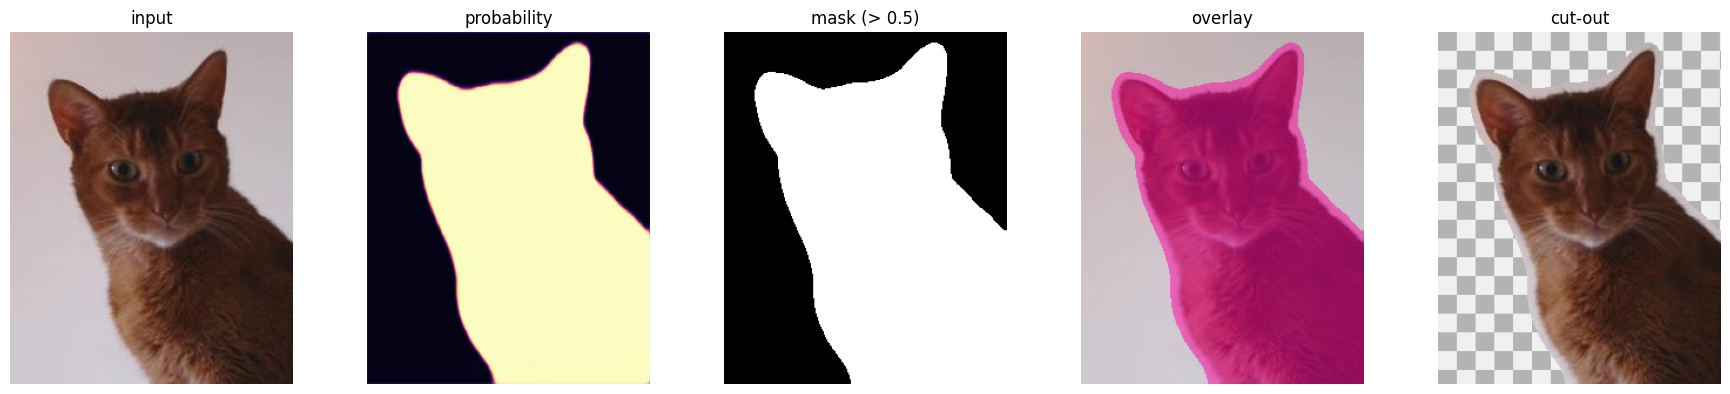

In [6]:
IMAGE = test_ds._images[7]          # <- or "path/to/your/photo.jpg"

rgb, probs, mask = segment(IMAGE, model)
print(f"image {rgb.shape[1]}x{rgb.shape[0]}, pet covers {mask.mean():.0%} of pixels")

overlay = rgb.copy()
overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 160])).astype(np.uint8)
cutout = np.dstack([rgb, (mask * 255).astype(np.uint8)])                  # RGBA: alpha 0 = transparent
Image.fromarray(cutout).save("../outputs/unet_cutout.png")

fig, ax = plt.subplots(1, 5, figsize=(18, 4))
checker = ((np.indices(mask.shape) // 16).sum(0) % 2) * 60 + 180         # grey checkerboard behind the cut-out
for a, im, title, kw in [
    (ax[0], rgb, "input", {}),
    (ax[1], probs, "probability", {"cmap": "magma", "vmin": 0, "vmax": 1}),
    (ax[2], mask, "mask (> 0.5)", {"cmap": "gray"}),
    (ax[3], overlay, "overlay", {}),
]:
    a.imshow(im, **kw); a.set_title(title); a.axis("off")
ax[4].imshow(checker, cmap="gray", vmin=0, vmax=255); ax[4].imshow(cutout); ax[4].set_title("cut-out"); ax[4].axis("off")
plt.tight_layout(); plt.savefig("../outputs/unet_inference.png", dpi=110); plt.show()

Several photos at once. The same function works for each, and the bottom row is the model's probability map:

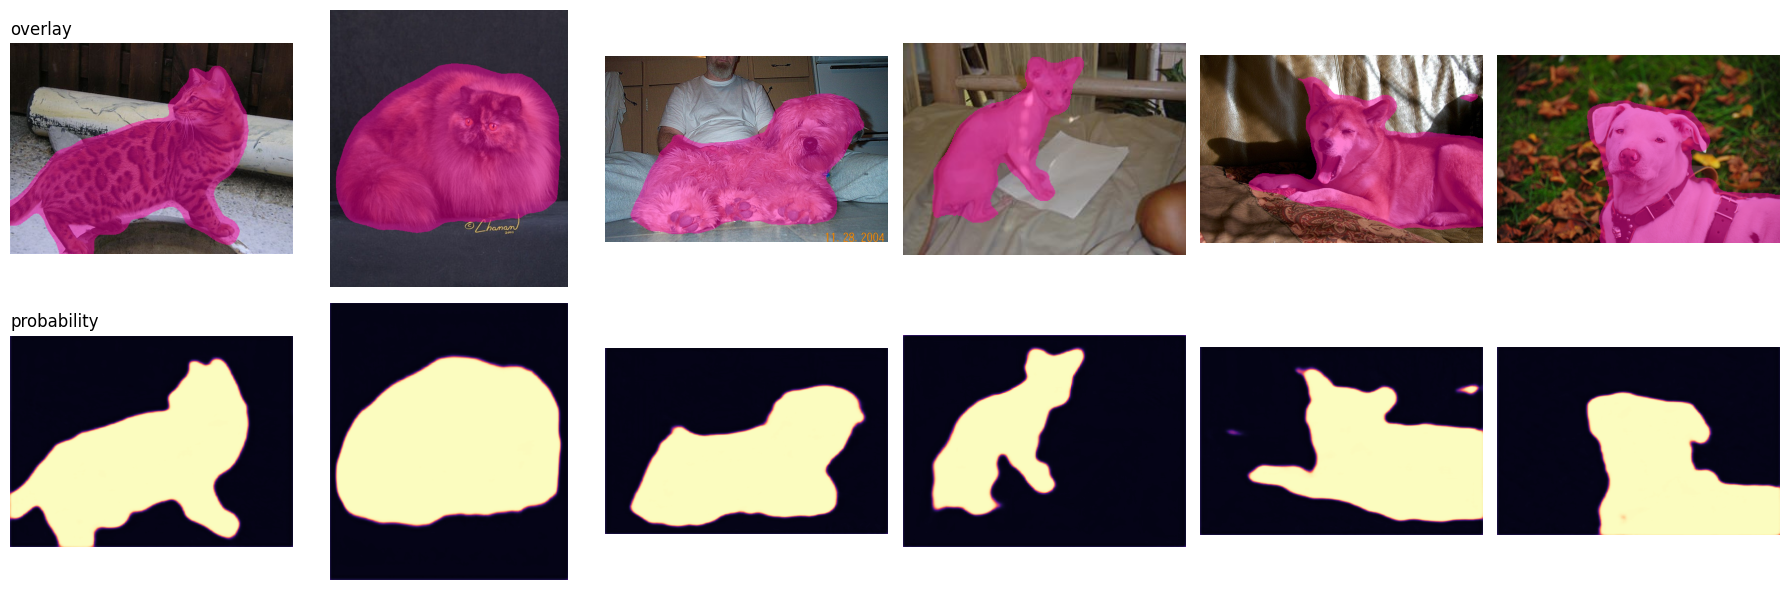

In [7]:
paths = [test_ds._images[i] for i in random.Random(1).sample(range(len(test_ds)), 6)]
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for i, p in enumerate(paths):
    rgb, probs, mask = segment(p, model)
    overlay = rgb.copy()
    overlay[mask] = (0.5 * overlay[mask] + 0.5 * np.array([255, 0, 160])).astype(np.uint8)
    ax[0, i].imshow(overlay); ax[1, i].imshow(probs, cmap="magma", vmin=0, vmax=1)
    ax[0, i].axis("off"); ax[1, i].axis("off")
ax[0, 0].set_title("overlay", loc="left"); ax[1, 0].set_title("probability", loc="left")
plt.tight_layout(); plt.savefig("../outputs/unet_inference_grid.png", dpi=110); plt.show()

**What to notice**
- **A halo around the pet.** The cut-out keeps a thin band of background around the fur. That comes from the labels, not the model: we (and the smp tutorial) count the trimap **border** class as pet, so the model learned to paint a few pixels past the real edge. A higher threshold (try `thr=0.8`) shrinks the mask, and training with border = background or ignoring border pixels in the loss would fix it at the source.
- **People are ignored** (3rd photo). The model learned "pet", not "whatever is in the foreground".
- **Second animal missed** (5th photo). The dark pet behind the dog is mostly lost, and there is a small false blob at the top right. Dark fur on a dark background is where the probability map is least sure, same as in section 5's error row.
- Probability maps are almost pure black or yellow with a thin orange rim. The model is very confident, and all its doubt sits at the edges.

## 11.5 Saving your own weights next time

To keep the model you train in section 5, add this after training, then download the file from Colab's file panel:

```python
torch.save(model.state_dict(), "unet_pets.pth")                 # plain PyTorch
model.save_pretrained("unet_pets")                              # smp: writes config.json + model.safetensors
# model.push_to_hub("your-username/unet-pets")                  # upload to the Hugging Face Hub
```

Load it back with `smp.from_pretrained("unet_pets")`, or build `smp.Unet(...)` and call `load_state_dict(torch.load("unet_pets.pth"))`. Then use the preprocessing **you** trained with, `(x/255 - MEAN) / STD`, in `preprocess`.

**Exercises**
1. Run `segment` on a photo with no pet in it (a car, a room). Where does the probability map light up, and why? The model has only ever seen pet photos.
2. Run it on a photo with two pets. A semantic segmentation model gives one mask for both. How would you split them? (Look up connected components with `scipy.ndimage.label`, or instance segmentation.)
3. Change `IMG_SIZE` to 512. Does a large photo get sharper edges or worse masks? (The model was trained at 256, so pets now look twice as big as it expects.)
4. Add flip TTA to `segment` (section 7): average the probabilities of the image and its horizontal flip.
5. Time `segment` for one image on your device, then reuse `bench` from section 6 with `model` to compare.